# Diffusion models 

We’ll use the same 2D dataset throughout. First we learn arrows that point toward higher density.
Then we use those arrows to move points with Langevin sampling. Finally we train a DDPM that learns
what correction to make at each noise level and generates new points from Gaussian noise.

In [1]:
# Colab already contains these packages. Locally, install numpy, matplotlib and torch.
import os, math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 20261119
SMOKE_TEST = os.environ.get('DIFFUSION_SMOKE_TEST', '0') == '1'

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(2, os.cpu_count() or 1))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

plt.rcParams.update({
    'figure.dpi': 115, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('Device:', device)

Device: cpu


## 1. Score matching — learn an arrow at each location

Imagine placing a point between two clusters of real data. If you move it a little to the left
or right, which way makes it more likely under the data distribution?

The **score** is the local arrow toward increasing density. A point has two coordinates here,
so its arrow has two components.

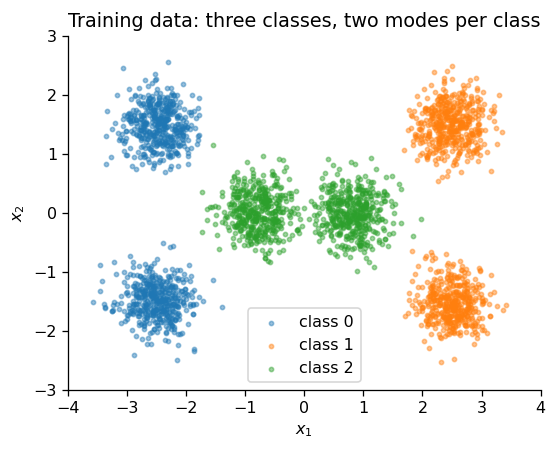

In [2]:
# A self-contained labelled dataset. Each class has two modes, so diversity is visible.
CENTERS = torch.tensor([
    [[-2.5, -1.5], [-2.5,  1.5]],  # class 0: left
    [[ 2.5, -1.5], [ 2.5,  1.5]],  # class 1: right
    [[-0.8,  0.0], [ 0.8,  0.0]],  # class 2: middle
], dtype=torch.float32)
N_CLASSES = len(CENTERS)

def sample_data(n, labels=None, seed=None):
    generator = torch.Generator().manual_seed(SEED if seed is None else seed)
    if labels is None:
        labels = torch.randint(N_CLASSES, (n,), generator=generator)
    else:
        labels = torch.as_tensor(labels, dtype=torch.long)
        n = len(labels)
    # Pick one of the two clusters belonging to each class.
    modes = torch.randint(2, (n,), generator=generator)
    means = CENTERS[labels, modes]
    points = means + 0.32 * torch.randn(n, 2, generator=generator)
    return points, labels

x_data, y_data = sample_data(6000)
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(figsize=(6, 4))
for c in range(N_CLASSES):
    pts = x_data[y_data == c]
    ax.scatter(*pts[:900].T, s=7, alpha=.45, color=colors[c], label=f'class {c}')
ax.set(title='Training data: three classes, two modes per class',
       xlabel='$x_1$', ylabel='$x_2$', xlim=(-4,4), ylim=(-3,3), aspect='equal')
ax.legend(); plt.show()

### Denoising score matching

We want the network to predict an arrow toward higher density. We have examples, but
we don't have the density formula to calculate those arrows directly.

So we make our own training targets:

1. Take a clean point $x$ and add Gaussian noise to get $\tilde x$.
2. Draw the arrow from the noisy point back toward the clean point.
3. Give the network only the noisy point and measure how far its predicted arrow is from that target.

The next cell uses $(x-\tilde x)/\sigma^2$ for the target. The subtraction gives
the direction. The denominator scales the arrow using the noise variance.

**What if two clean points could have produced the same noisy point?** The network
learns an average of their arrows, giving more weight to the more likely source.
That average describes the density of the **noisy points at this noise level**.
We'll look at those arrows in the next plot.

In [3]:
# Train the score network at one fixed noise level.
sigma = 0.40
torch.manual_seed(SEED + 1)
score_model = nn.Sequential(
    nn.Linear(2, 96), nn.SiLU(),
    nn.Linear(96, 96), nn.SiLU(),
    nn.Linear(96, 2),
).to(device)
score_optimizer = torch.optim.Adam(score_model.parameters(), lr=0.002)
score_steps = 80 if SMOKE_TEST else 2000

for update in range(score_steps):
    # Draw clean examples, add Gaussian noise, and compute the target arrows.
    clean, _ = sample_data(512, seed=SEED + 100 + update)
    clean = clean.to(device)
    noisy = clean + sigma * torch.randn_like(clean)
    target_arrow = (clean - noisy) / sigma**2

    # The network receives only the noisy points.
    predicted_arrow = score_model(noisy)
    score_loss = (predicted_arrow - target_arrow).square().mean()
    score_optimizer.zero_grad()
    score_loss.backward()
    score_optimizer.step()
score_model.eval()

Sequential(
  (0): Linear(in_features=2, out_features=96, bias=True)
  (1): SiLU()
  (2): Linear(in_features=96, out_features=96, bias=True)
  (3): SiLU()
  (4): Linear(in_features=96, out_features=2, bias=True)
)

### How to read the arrows plot

The pale dots are examples at the same noise level used to train the network. Each arrow
starts at a location on a grid and shows the score predicted there. To read one arrow,
look at its tail and ask which way the network would move a point starting there.

**Try it:** compare a point outside a cluster with a point near its center. Near a center,
the net direction can be small because nearby possible clean points pull in different directions.
Arrow lengths are compressed for readability. In sparsely sampled areas, treat predictions cautiously.

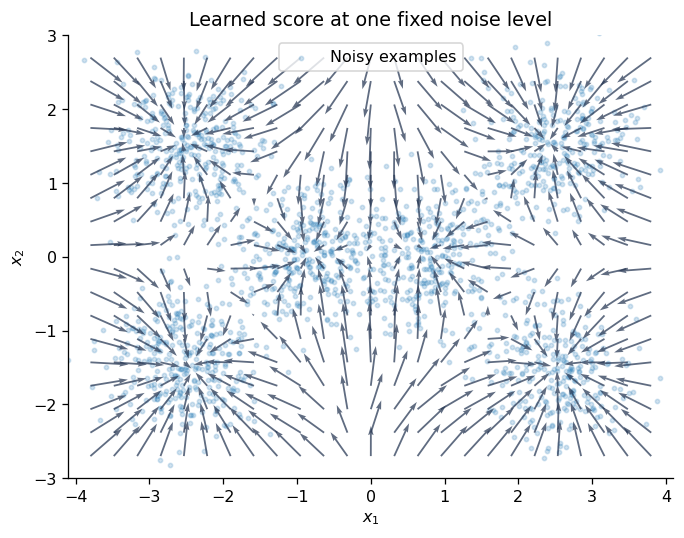

In [4]:
@torch.inference_mode()
def plot_score_arrows(ax):
    # Ask the network for one arrow at each grid point.
    grid_x, grid_y = np.meshgrid(np.linspace(-3.8, 3.8, 25), np.linspace(-2.7, 2.7, 18))
    grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    arrows = score_model(torch.as_tensor(grid, dtype=torch.float32, device=device)).cpu().numpy()
    lengths = np.linalg.norm(arrows, axis=1, keepdims=True)
    # Compress long arrows while preserving their directions.
    arrows *= 0.28 * np.log1p(lengths) / np.maximum(lengths, 1e-8)
    display_rng = torch.Generator().manual_seed(42)
    noisy_points = x_data[:1800] + sigma * torch.randn((1800, 2), generator=display_rng)
    ax.scatter(*noisy_points.T, s=7, alpha=0.20, color='tab:blue', label='Noisy examples')
    ax.quiver(*grid.T, *arrows.T, angles='xy', scale_units='xy', scale=1,
              color='#253653', alpha=0.73, width=0.003)
    ax.set(xlim=(-4.1, 4.1), ylim=(-3, 3), aspect='equal', xlabel='$x_1$', ylabel='$x_2$')

fig, ax = plt.subplots(figsize=(8, 5))
plot_score_arrows(ax)
ax.set_title('Learned score at one fixed noise level')
ax.legend(loc='upper center')
plt.show()

### What does the score do in a low-density region?

The contours below show the **true density for this toy dataset after adding noise**.
We can calculate it because we chose the six Gaussian clusters ourselves. The learned arrows
in the previous plot came from the network trained only on examples. Here we draw the exact
score to see what the network is trying to learn.

- **A — near a cluster center:** the density is high and the slope can be tiny.
- **B — between clusters:** density can be lower while opposing pulls nearly cancel.
- **C — in the tail:** density is very low, yet the score can point strongly back toward a cluster.

Gaussian clusters have tails everywhere. Here “outside a cluster” means **very low density**.
Read density from the contour color and the score's direction from the arrow. The printed
values give the original density and score magnitude at each probe.
Compare the two panels to see how heavier noise softens the gaps between clusters.

Noise standard deviation 0.40
  A: density = 0.101, score magnitude = 0.000
  B: density = 0.00319, score magnitude = 0.834
  C: density = 0.00026, score magnitude = 6.742
Noise standard deviation 1.20
  A: density = 0.0216, score magnitude = 0.307
  B: density = 0.0238, score magnitude = 0.358
  C: density = 0.00636, score magnitude = 1.175


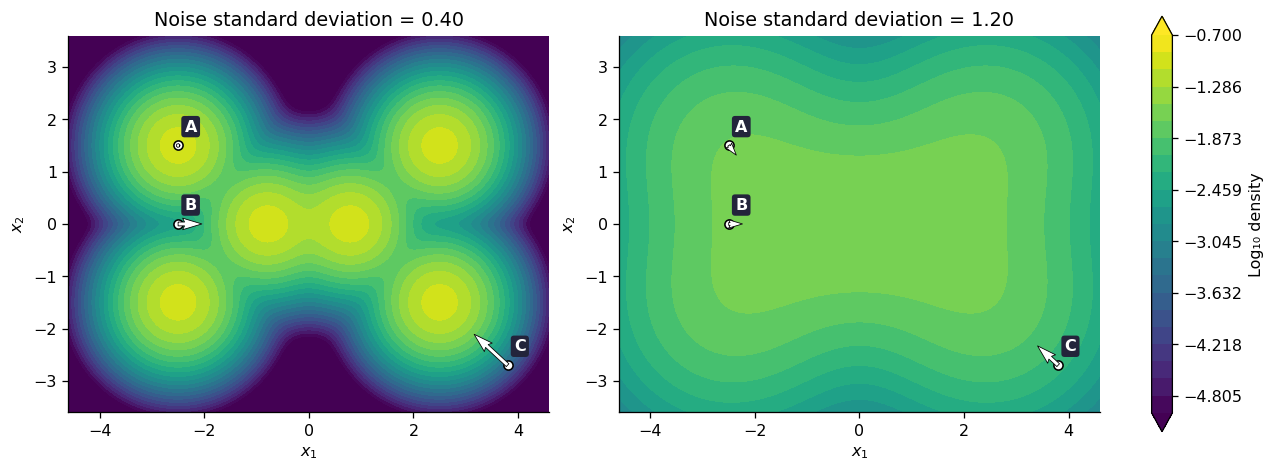

In [5]:
def toy_density_and_score(points, blur_sigma):
    # Every cluster gets wider when we add Gaussian noise. Gaussian variances add.
    centers = CENTERS.reshape(-1, 2).numpy()
    variance = 0.32**2 + blur_sigma**2
    displacement = points[:, None, :] - centers[None, :, :]
    log_kernel = -np.square(displacement).sum(axis=-1) / (2 * variance)
    density = np.exp(log_kernel).mean(axis=1) / (2 * np.pi * variance)

    # At each point, weight the arrow toward each center by its share of local density.
    weights = np.exp(log_kernel - log_kernel.max(axis=1, keepdims=True))
    weights /= weights.sum(axis=1, keepdims=True)
    arrows = (weights[..., None] * (-displacement / variance)).sum(axis=1)
    return density, arrows


grid_x, grid_y = np.meshgrid(np.linspace(-4.6, 4.6, 240), np.linspace(-3.6, 3.6, 190))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])
probes = np.array([[-2.5, 1.5], [-2.5, 0.0], [3.8, -2.7]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')

for ax, blur in zip(axes, [sigma, 1.20]):
    # Use identical logarithmic color limits so the two noise levels are comparable.
    density, _ = toy_density_and_score(grid, blur)
    contour = ax.contourf(grid_x, grid_y, np.log10(density.reshape(grid_x.shape)),
                          levels=np.linspace(-5, -0.7, 23), cmap='viridis', extend='both')
    probe_density, arrows = toy_density_and_score(probes, blur)
    lengths = np.linalg.norm(arrows, axis=1)
    # Shorten long arrows for display while keeping their direction.
    shown = arrows / (1 + lengths[:, None])
    ax.scatter(*probes.T, s=33, color='white', edgecolors='black', zorder=4)
    ax.quiver(*probes.T, *shown.T, angles='xy', scale_units='xy', scale=1,
              color='white', edgecolor='black', linewidth=0.5, width=0.008, zorder=5)
    for name, point in zip('ABC', probes):
        ax.annotate(name, point, xytext=(4, 9), textcoords='offset points',
                    color='white', weight='bold',
                    bbox={'boxstyle': 'round,pad=.2', 'fc': '#23243b', 'ec': 'none'})
    ax.set(title=f'Noise standard deviation = {blur:.2f}', aspect='equal',
           xlabel='$x_1$', ylabel='$x_2$', xlim=(-4.6, 4.6), ylim=(-3.6, 3.6))
    print(f'Noise standard deviation {blur:.2f}')
    for name, density_here, magnitude in zip('ABC', probe_density, lengths):
        print(f'  {name}: density = {density_here:.3g}, score magnitude = {magnitude:.3f}')

fig.colorbar(contour, ax=axes, label='Log₁₀ density', shrink=.80)
plt.show()

## 2. Langevin sampling — use the arrows to move a point

A trained score network can answer “which way is uphill from here?” Langevin sampling uses that
answer repeatedly to draw samples from a distribution. Following only the arrows tends to lead
points toward nearby peaks. The random part lets points explore the area around those peaks.

$$
x_{\mathrm{next}}=x+\frac{h}{2}s_\theta(x)+\sqrt{h}\,z,
\qquad z\sim\mathcal N(0,I).
$$

$h$ is the step size. The middle term follows the arrow. The last term adds a fresh,
zero-centered Gaussian nudge. This is a short demonstration with a learned score,
so read the trajectories as examples of the rule in action.

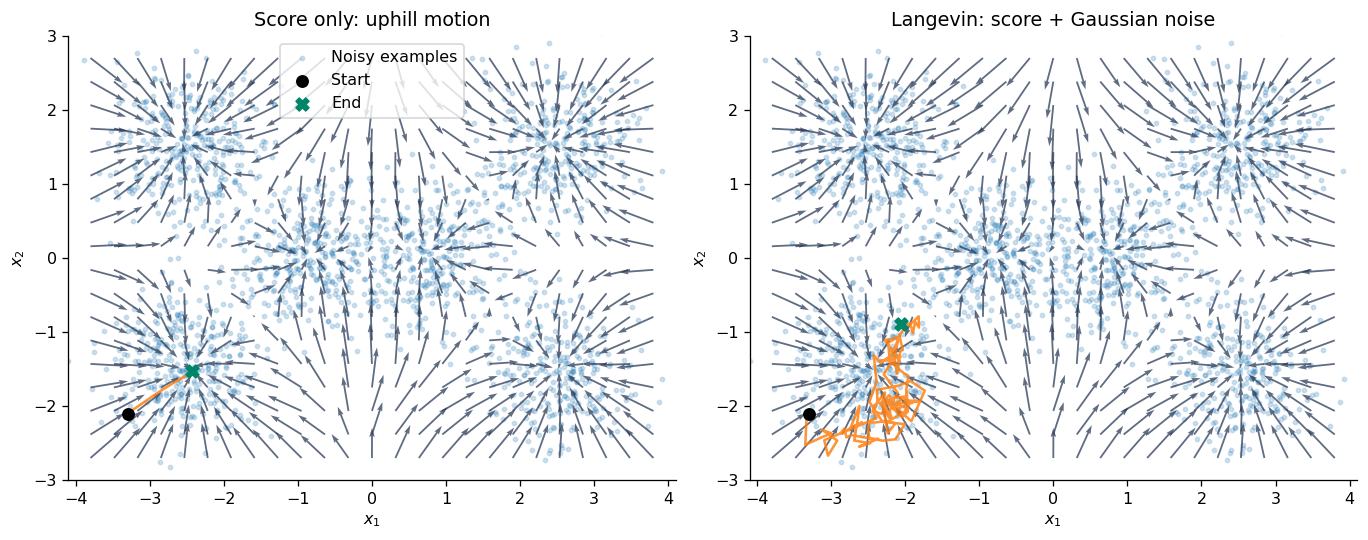

In [6]:
@torch.inference_mode()
def sample_langevin(start, steps=120, step_size=0.02, add_randomness=True):
    # Begin both experiments at the same point, near a cluster.
    current = torch.tensor(start, device=device)
    rng = torch.Generator(device=device).manual_seed(21)
    trajectory = [current.cpu()]
    for _ in range(steps):
        drift = 0.5 * step_size * score_model(current[None])[0]
        # Use Gaussian noise: randn draws positive and negative values around zero.
        if add_randomness:
            noise = torch.randn(current.shape, generator=rng, device=device)
            current = current + drift + math.sqrt(step_size) * noise
        else:
            current = current + drift
        trajectory.append(current.cpu())
    return torch.stack(trajectory)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, stochastic in zip(axes, [False, True]):
    plot_score_arrows(ax)
    path = sample_langevin([-3.3, -2.1], add_randomness=stochastic)
    # The line follows the point in time. The markers identify the two ends.
    ax.plot(*path.T, color='tab:orange', lw=1.6, alpha=0.84)
    ax.scatter(*path[0], marker='o', color='black', s=50, zorder=5, label='Start')
    ax.scatter(*path[-1], marker='X', color='#00856a', s=65, zorder=5, label='End')
    ax.set_title('Langevin: score + Gaussian noise' if stochastic else 'Score only: uphill motion')
axes[0].legend(loc='upper center')
plt.tight_layout()
plt.show()

In the left panel, the path settles near a peak. In the right panel, the point keeps moving.
**Predict before rerunning:** what changes if you change the random seed but keep the start fixed?

### How this leads to DDPM

This Langevin example uses one score field, at one fixed noise level. If we start far from
the real clusters, a lightly blurred score can be hard to learn and use. Heavy noise broadens
the clusters. Lighter noise brings their details back.

**Annealed Langevin sampling** walks at one noise level, switches to a lower noise level,
and continues with a new score field. **DDPM** also moves from high to low noise. Its sampler
uses a particular reverse Gaussian step derived from its forward schedule. The next sections
show how the network’s noise prediction supplies the score information for that step.

## 3. Diffusion — two processes

**Forward, fixed.** Start at clean data $x_0$. Add Gaussian noise in steps to reach $x_T$,
which we aim to make approximately standard Gaussian. The notation
$q(x_t\mid x_{t-1})$ means “the distribution of the next noisier point given the current point.”

**Reverse, learned.** Start with a new Gaussian point $x_T$. Use a network to take steps toward
$x_0$. The notation $p_\theta(x_{t-1}\mid x_t)$ means “the model’s distribution for the next
slightly cleaner point given the current noisy point.”

Every state in the experiment is a pair of coordinates. For image diffusion, each state
can be an image-shaped tensor instead.

### Read the arrows on this picture

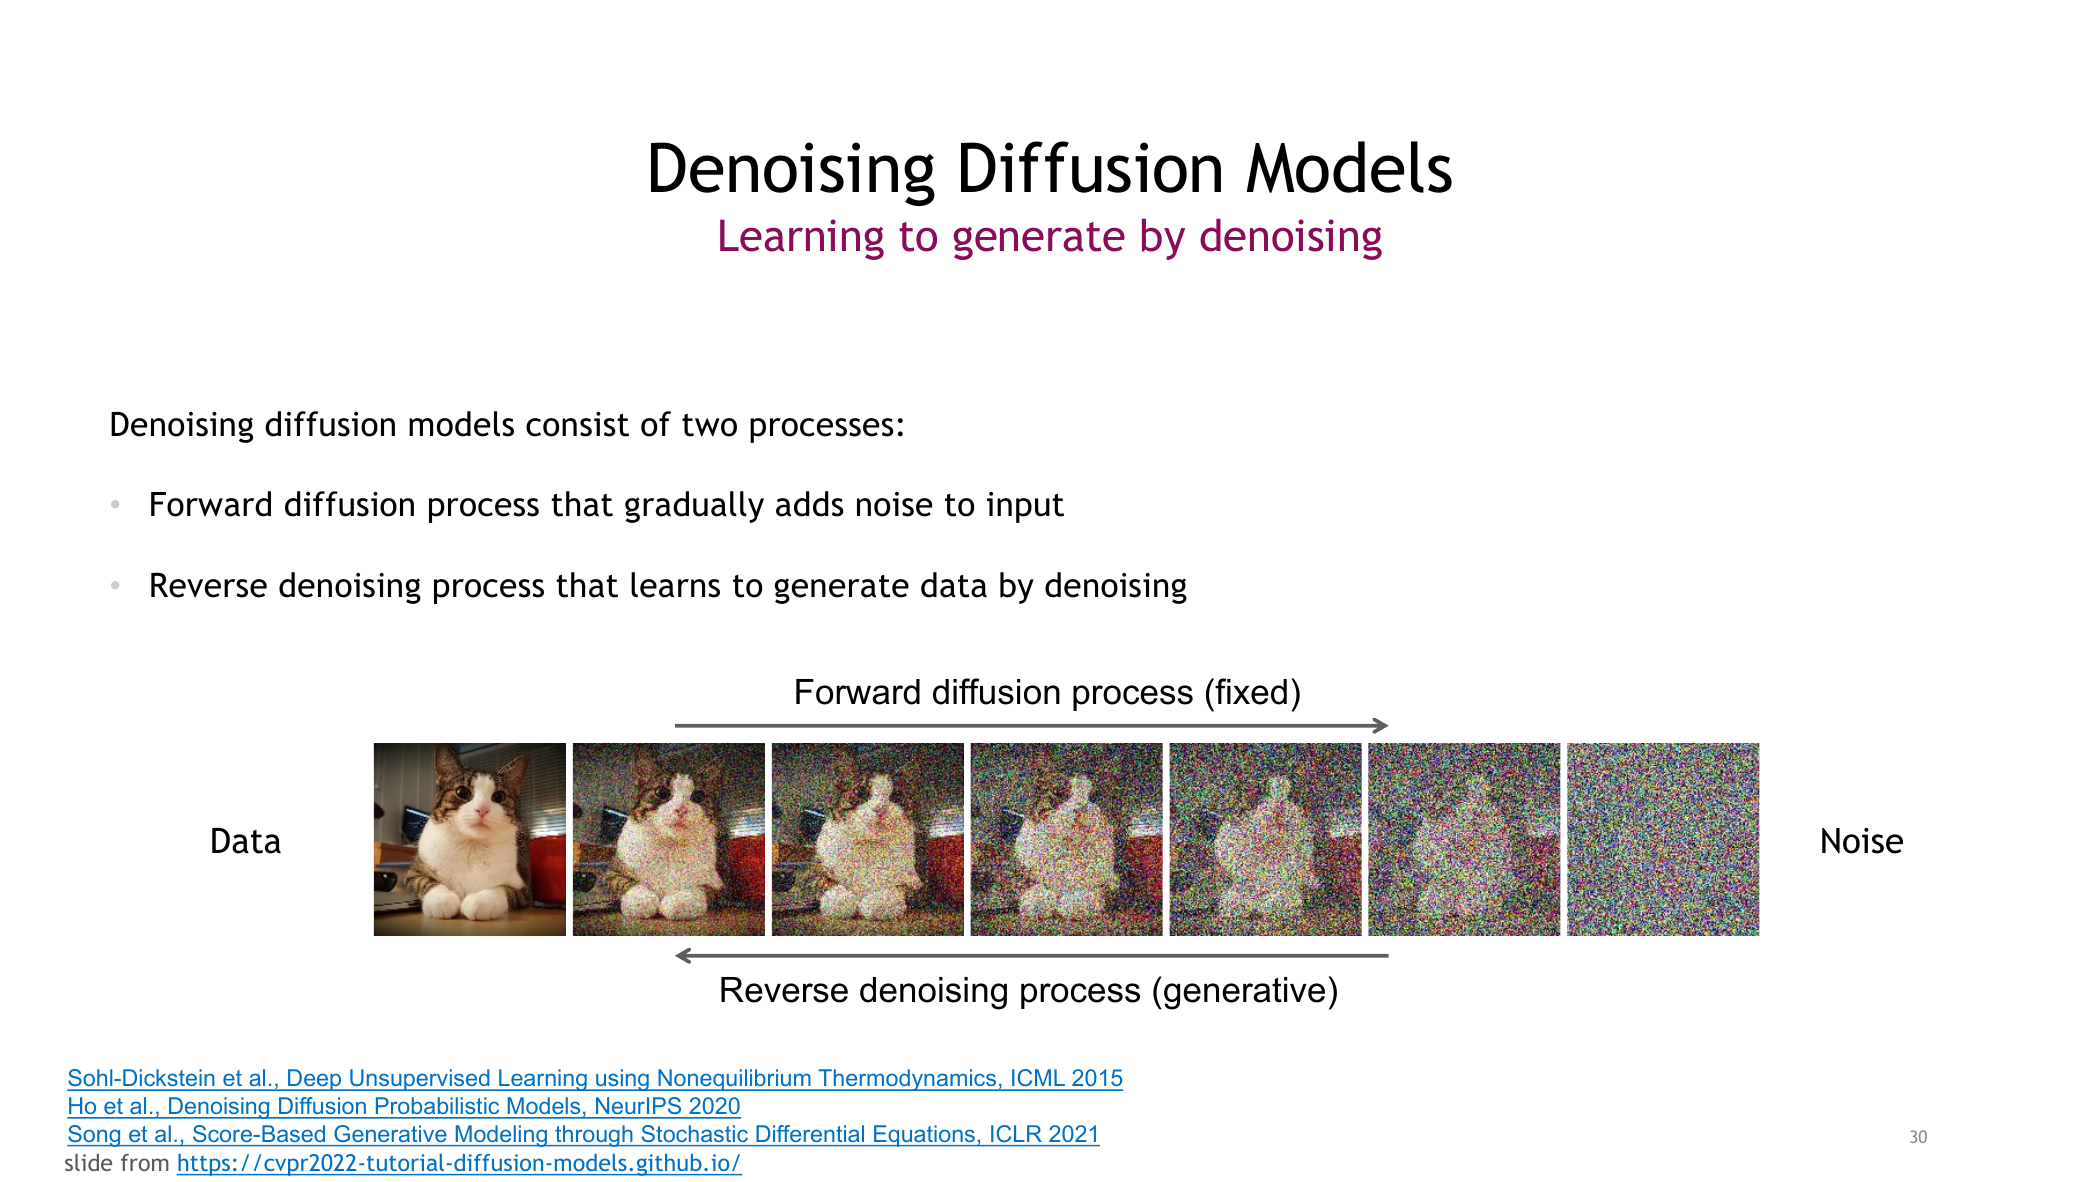

Read left to right for fixed noising and right to left for learned generation. Generation starts with a fresh random draw and creates a new sample. *Source: supplied CS231n lecture, PDF page 28, credited to the CVPR 2022 diffusion tutorial.*

### One forward step

$$
x_t=\sqrt{\alpha_t}\,x_{t-1}+\sqrt{\beta_t}\,z_t,
\qquad \alpha_t=1-\beta_t,\quad z_t\sim\mathcal N(0,I).
$$

We choose the list of $\beta_t$ values before training. Each $\beta_t$ is the variance of the
fresh noise added at that step. Its square root scales the noise vector. The other term
slightly shrinks the previous state.

### The useful shortcut

To create a training example at step 60, going through steps 1–59 would be wasteful.
Gaussian noises combine into another Gaussian. Multiplying the retained signal factors gives
$\bar\alpha_t=\alpha_1\cdots\alpha_t$, with $\bar\alpha_0=1$. We can jump directly to $t$:

$$
x_t=\underbrace{\sqrt{\bar\alpha_t}\,x_0}_{\text{remaining clean signal}}
+\underbrace{\sqrt{1-\bar\alpha_t}\,\epsilon}_{\text{combined Gaussian noise}},
\qquad \epsilon\sim\mathcal N(0,I).
$$

Here $\epsilon$ represents the **combined** noise up to $t$. In the code,
`take(...)` picks the right coefficient for each example. The first array entry,
index 0, describes the first noisy state $x_1$.

**Where the shortcut’s noise coefficient comes from.** Write $v_t$ for the accumulated
noise variance when $x_0$ is fixed. At step $t$, the variance already present is
multiplied by $\alpha_t$, then the fresh independent noise contributes $\beta_t$.
So $v_t=\alpha_t v_{t-1}+\beta_t$. Starting from $v_0=0$, this gives
$v_t=1-\bar\alpha_t$, which is why the noise is scaled by $\sqrt{1-\bar\alpha_t}$.

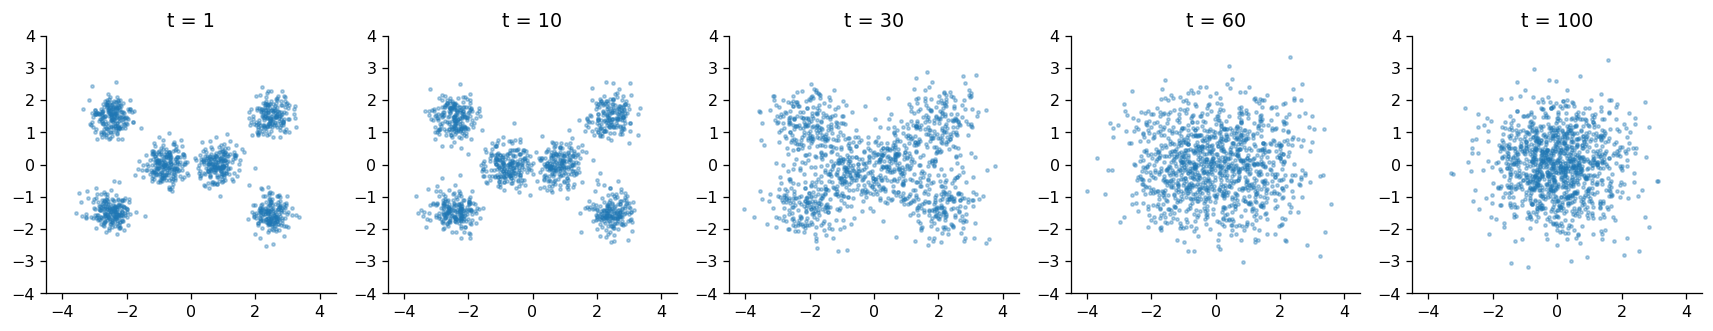

Final retained signal fraction (alpha_bar_T): 0.016295403242111206


In [7]:
# Arrays use indices 0…99 for mathematical timesteps 1…100.
T = 100
betas = torch.linspace(1e-4, 0.08, T, device=device)
alphas = 1.0 - betas
# Multiply all signal-retention factors up to each timestep.
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])
# Precompute the variance used by the reverse sampler.
posterior_variance = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)

def take(values, t, like):
    # Take one schedule value per example and add singleton feature dimensions.
    return values[t].reshape(len(t), *([1] * (like.ndim - 1)))

def q_sample(x0, t, noise=None):
    # Sample x_t directly from x_0.
    if noise is None:
        noise = torch.randn_like(x0)
    # Gather one signal and one noise coefficient per row of the batch.
    signal = take(alpha_bars.sqrt(), t, x0)
    noise_scale = take((1 - alpha_bars).sqrt(), t, x0)
    return signal * x0 + noise_scale * noise, noise

# Reuse points and noise across panels to isolate changes in the mixing coefficients.
base = x_data[:1200].to(device)
fixed_noise = torch.randn_like(base)
shown_t = [0, 9, 29, 59, 99]
fig, axes = plt.subplots(1, len(shown_t), figsize=(15, 3))
for ax, step in zip(axes, shown_t):
    tt = torch.full((len(base),), step, device=device, dtype=torch.long)
    noisy, _ = q_sample(base, tt, fixed_noise)
    ax.scatter(*noisy.cpu().T, s=4, alpha=.35)
    ax.set(title=f't = {step + 1}', xlim=(-4.5,4.5), ylim=(-4,4), aspect='equal')
plt.tight_layout(); plt.show()
print('Final retained signal fraction (alpha_bar_T):', float(alpha_bars[-1]))

**Read the panels.** The early panels preserve the clusters. The last panel is much closer
to a round cloud. We reused the same noise in each panel to isolate the change in coefficients.
Each panel illustrates the distribution at its timestep. A step-by-step forward simulation
would draw fresh noise at each step.

## 4. Train the DDPM — predict the noise we added

1. Pick a clean point and a random noise level.
2. Use the forward shortcut to add Gaussian noise. Keep that noise as the answer key.
3. Give the network the noisy point and its timestep. Use mean squared error to compare
   its predicted noise with the answer key.

In the score demo, the network predicted an arrow pointing back from the noise.
Here it predicts the noise itself. At a fixed noise level, flipping its sign and
rescaling gives the corresponding score estimate. The timestep tells the network
which noise level to handle.

The network sees a class label on most examples. Hiding it occasionally lets us
later ask the same network to generate without a class request.

In [8]:
class TimeEmbedding(nn.Module):
    # Turn scalar timesteps into smooth sine/cosine features.
    def __init__(self, dim=32):
        super().__init__()
        half = dim // 2
        frequencies = torch.exp(-math.log(10_000) * torch.arange(half) / max(half - 1, 1))
        self.register_buffer('frequencies', frequencies)

    def forward(self, t):
        angles = t.float()[:, None] * self.frequencies[None]
        return torch.cat([angles.sin(), angles.cos()], dim=1)

class NoisePredictor(nn.Module):
    def __init__(self, n_classes=N_CLASSES, hidden=128, time_dim=32, label_dim=16):
        super().__init__()
        self.null_label = n_classes  # an extra ID means “no condition”
        # Convert time and class IDs into features the network can use.
        self.time = TimeEmbedding(time_dim)
        self.label = nn.Embedding(n_classes + 1, label_dim)
        self.net = nn.Sequential(
            nn.Linear(2 + time_dim + label_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, xt, t, labels):
        # Input: noisy coordinates, time features, and class features. Output: two noise coordinates.
        features = torch.cat([xt, self.time(t), self.label(labels)], dim=1)
        return self.net(features)

model = NoisePredictor().to(device)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

NoisePredictor(
  (time): TimeEmbedding()
  (label): Embedding(4, 16)
  (net): Sequential(
    (0): Linear(in_features=50, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 39874


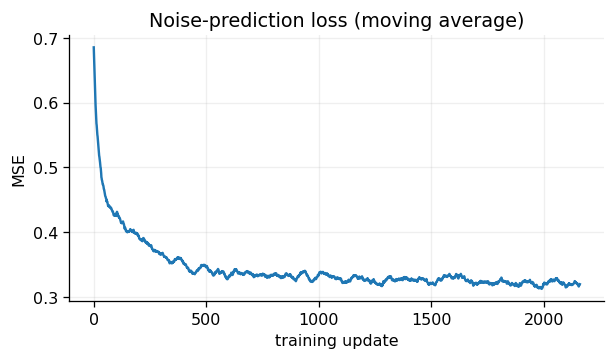

First loss: 0.979 | final mean: 0.319


In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
training_steps = 80 if SMOKE_TEST else 2200
batch_size = 512
condition_drop_probability = 0.15
loss_history = []

# Each update uses a fresh batch and a different noise level for each point.
model.train()
for step in range(training_steps):
    x0, labels = sample_data(batch_size, seed=SEED + step)
    x0, labels = x0.to(device), labels.to(device)
    t = torch.randint(T, (batch_size,), device=device)
    xt, true_noise = q_sample(x0, t)  # Keep the original noise as the answer key.

    # Some examples teach the same network the unconditional task.
    used_labels = labels.clone()
    drop = torch.rand(batch_size, device=device) < condition_drop_probability
    used_labels[drop] = model.null_label

    predicted_noise = model(xt, t, used_labels)
    # Average squared error over the batch and both coordinates.
    loss = (predicted_noise - true_noise).square().mean()
    # Clear old gradients, calculate new ones, and update the weights.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(float(loss.detach()))

model.eval()
fig, ax = plt.subplots(figsize=(6, 3))
window = 40
smooth = np.convolve(loss_history, np.ones(window)/window, mode='valid') if len(loss_history) >= window else loss_history
ax.plot(smooth)
ax.set(title='Noise-prediction loss (moving average)', xlabel='training update', ylabel='MSE')
ax.grid(alpha=.2); plt.show()
print(f'First loss: {loss_history[0]:.3f} | final mean: {np.mean(loss_history[-50:]):.3f}')

**Read the loss plot.** Falling MSE means that the network is getting better at noise prediction
on the batches it sees. The same noisy point can come from different clean points, so exact
recovery of the training noise is generally impossible. Inspect the generated clouds to see
whether the model also captures the shape of the data.

## 5. Reverse sampling — where do the formulas come from?

**What we want.** At generation time we have $x_t$ and want a reasonable draw of $x_{t-1}$.
We have no original clean $x_0$ to tell us which reverse move is right.

**What we can calculate during training.** With a known $x_0$, we know where $x_{t-1}$ typically
lies. Seeing $x_t$ gives a second clue about where $x_{t-1}$ could be. Multiplying the two Gaussian
terms produces another Gaussian, $q(x_{t-1}\mid x_t,x_0)$. This is our reference for a single
reverse step. After substituting the forward shortcut, its center and variance can be written as:

$$
\begin{aligned}
\text{reference center}
  &=\frac{1}{\sqrt{\alpha_t}}
    \left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon\right),\\
\text{reference variance}
  &=\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
\end{aligned}
$$

**How we use it during generation.** Replace the unknown $\epsilon$ with the network’s estimate
$\epsilon_\theta(x_t,t,c)$, where $c$ is the optional class label. This gives the model’s
reverse mean $\mu_\theta(x_t,t,c)$. Our sampler uses the fixed reference variance above as
its variance choice:

$$
x_{t-1}=\mu_\theta(x_t,t,c)+\sqrt{\tilde\beta_t}\,z,
\qquad z\sim\mathcal N(0,I).
$$

The mean makes the learned correction. The new draw $z$ samples around that mean to represent
uncertainty about the previous state. It is independent of the training noise $\epsilon$.
On the final step we return the mean. With $\bar\alpha_0=1$, the reference variance is zero there.

### Read the sampling cell in three passes

1. **Start.** `n` is the number of new points. `torch.randn(n, 2)` makes a batch of random starting coordinates.
2. **Repeat.** Give every point the current timestep, predict its noise, compute the reverse mean,
   and sample around it.
3. **Watch.** `snapshots` saves selected states for plotting. `step=0` uses the schedule’s first entry
   to turn the last noisy state into the final output $x_0$.

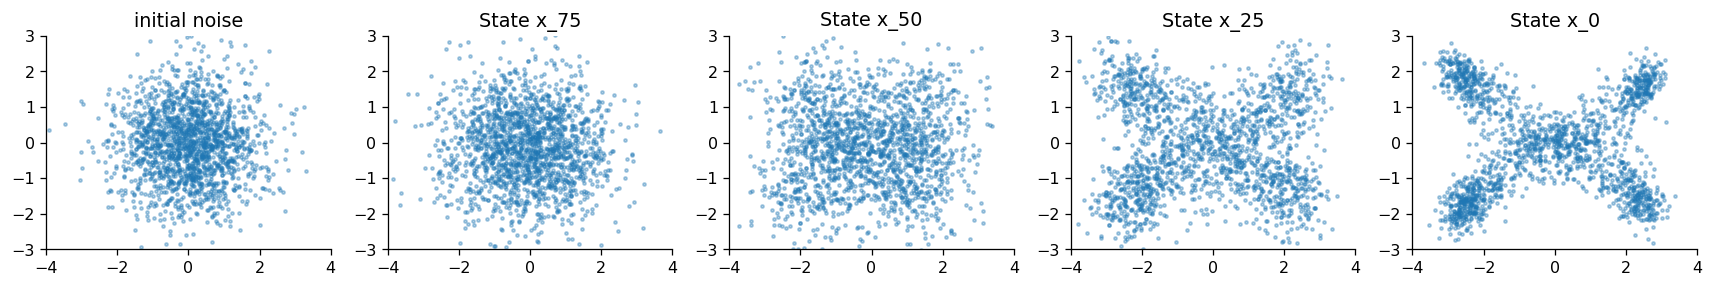

In [10]:
@torch.inference_mode()
def sample_ddpm(n, labels=None, guidance_scale=1.0, seed=0, keep_trajectory=False):
    # Use a local seed so repeated experiments can share the same random draws.
    generator = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 2, generator=generator, device=device)  # n new 2D samples
    null = torch.full((n,), model.null_label, device=device, dtype=torch.long)
    # A single label applies to the whole batch. None uses the no-class token.
    if labels is None:
        labels = null
    else:
        labels = torch.as_tensor(labels, device=device, dtype=torch.long)
        if labels.ndim == 0:
            labels = labels.repeat(n)
    snapshots = {T: x.cpu()}

    # Index step describes mathematical x_(step+1). The update produces x_step.
    for step in reversed(range(T)):
        t = torch.full((n,), step, device=device, dtype=torch.long)
        eps_uncond = model(x, t, null)
        # The unconditional run needs one prediction. Guidance uses a second one.
        eps = eps_uncond
        if guidance_scale != 0:
            eps_cond = model(x, t, labels)
            eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)

        # Compute the center of the next-state Gaussian using predicted noise.
        mean = (x - betas[step] / torch.sqrt(1 - alpha_bars[step]) * eps) / torch.sqrt(alphas[step])
        # Draw a new Gaussian perturbation at each step before the final output.
        if step > 0:
            noise = torch.randn(x.shape, generator=generator, device=device)
            x = mean + posterior_variance[step].sqrt() * noise
        else:
            x = mean
        # Save selected states for plotting. Generation still visits every step.
        if keep_trajectory and step in {75, 50, 25, 0}:
            snapshots[step] = x.cpu()
    return x.cpu(), snapshots

# Unconditional generation: the model receives no class target.
generated, trajectory = sample_ddpm(1800, labels=None, guidance_scale=0.0,
                                     seed=123, keep_trajectory=True)
# Each panel shows the same batch at a different stage of generation.
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, step in zip(axes, [T, 75, 50, 25, 0]):
    pts = trajectory[step]
    ax.scatter(*pts.T, s=4, alpha=.35)
    ax.set(title='initial noise' if step == T else f'State x_{step}',
           xlim=(-4,4), ylim=(-3,3), aspect='equal')
plt.tight_layout(); plt.show()

**Read the result.** Scan left to right from Gaussian noise to the final sample. Ask when the broad
arrangement appears and when the clusters tighten. The first and last plots show the same
collection of generated points at different stages of the reverse trajectory.

## 6. Optional experiment — ask for one class

`labels=0` requests the two left-hand clusters. Classifier-free guidance combines two predictions
from the same network. Let $u$ be the noise prediction with no class and $c$ the noise prediction
with the requested class. Use $u+w(c-u)$. The difference $c-u$ is the change in prediction
caused by giving the model the class.

At $w=0$ we get the no-class prediction. At $w=1$ we get the ordinary class prediction.
Higher values amplify the effect of the class. Compare how many points land near the two crosses
and how the clusters change shape as the scale increases.

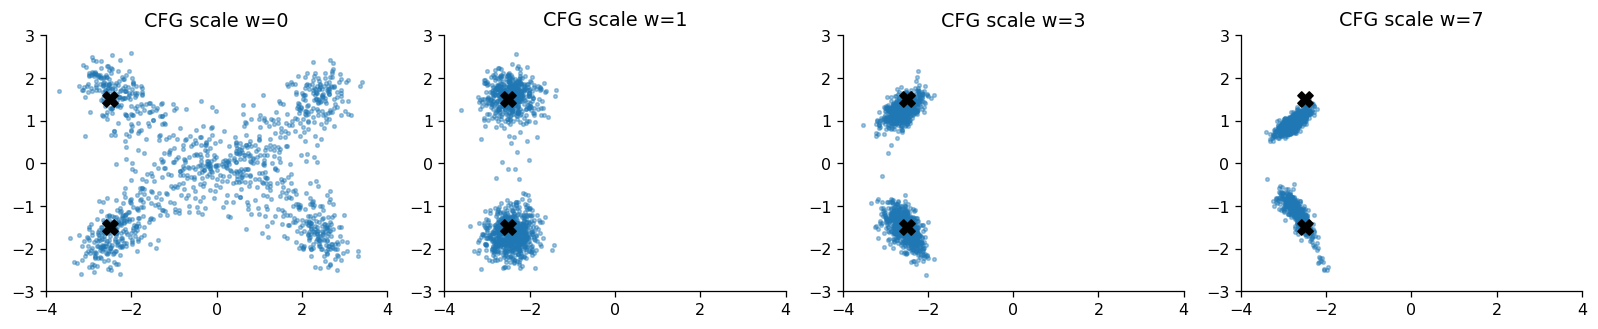

In [11]:
# Keep the class, starting noise, and reverse noise draws fixed across panels.
target_class = 0
guidance_scales = [0.0, 1.0, 3.0, 7.0]
fig, axes = plt.subplots(1, len(guidance_scales), figsize=(14, 3.2))
guidance_samples = {}
for ax, scale in zip(axes, guidance_scales):
    pts, _ = sample_ddpm(1200, labels=target_class, guidance_scale=scale,
                         seed=100)
    guidance_samples[scale] = pts
    ax.scatter(*pts.T, s=5, alpha=.4)
    # Crosses mark the two true centers of the requested class.
    ax.scatter(*CENTERS[target_class].T, marker='X', s=90, color='black')
    ax.set(title=f'CFG scale w={scale:g}', xlim=(-4,4), ylim=(-3,3), aspect='equal')
plt.tight_layout(); plt.show()

## What to remember

- **Score matching** learns local directions toward higher density.
- **Denoising score matching** creates a target arrow by adding known noise to a clean example.
- **Langevin sampling** uses a score and random nudges to explore one noise level in our demo.
- **DDPM training** chooses a random noise level, creates the noisy input directly, and minimizes
  squared error between predicted noise and the noise it drew.
- **DDPM generation** starts from fresh Gaussian noise and repeatedly uses the prediction
  to sample a slightly cleaner state.

**Check yourself:** Why is the training target known? Why do we supply a timestep? During
generation, where does the input to the next step come from?

The score-field and Langevin sequence is adapted from the seminar’s explained notebook,
which credits the [ACIDS diffusion notebook](https://github.com/acids-ircam/diffusion_models/blob/main/diffusion_02_model.ipynb).
The DDPM practical is adapted from the seminar’s student Colab notebook.

## Optional math appendix

These derivations are here for reference after the practical.

### Optional math · Classical and sliced score matching

**What we want to calculate.** Compare the network's arrow with the true arrow at each data point:

$$
\tfrac12\mathbb E_{x\sim p}\big[\|s_\theta(x)-\nabla_x\log p(x)\|^2\big].
$$

**What we can calculate instead.** Expand the square. The squared true score is constant with respect
to the network. In the cross-term, $p\nabla\log p=\nabla p$. Integration by parts moves the derivative
from the unknown density onto the network. Under suitable boundary and smoothness conditions, the loss
for optimization becomes

$$
\mathcal L_{\rm SM}=\mathbb E_{x\sim p}\!\left[
    \tfrac12\|s_\theta(x)\|^2+\operatorname{tr}(J_{s_\theta}(x))
\right].
$$

$J_{s_\theta}$ is the table of how the output arrows change as we move the input.
Its trace adds the diagonal entries. Only the trace is needed, and obtaining those entries
individually can be expensive for images.

**Sliced score matching** uses a random direction $v\sim\mathcal N(0,I)$ at each point:

$$
\mathcal L_{\rm sliced}
=\mathbb E_{x,v}\!\left[
v^\mathsf T J_{s_\theta}(x)v+\tfrac12(v^\mathsf T s_\theta(x))^2
\right].
$$

Since the average of $vv^\mathsf T$ is $I$, the first term averages to the trace and the second
averages to half the squared score length. The first term can be computed with a directional
derivative, without building the full table. Denoising score matching takes a different route.
It creates a known Gaussian target and uses ordinary squared error, as the training cell above does.

### Denoising score matching in equations

**What we want.** Train a network to predict the local direction toward higher data density:

$$
s_\theta(x)\approx\nabla_x\log p_{\mathrm{data}}(x).
$$

We can draw clean examples from the dataset, but we do not know the density formula
$p_{\mathrm{data}}(x)$. The arrow on the right is therefore unavailable as a training label.

### Denoising score matching

**What we can calculate instead.** Pick a clean point $x$. Draw $\eta\sim\mathcal N(0,I)$
and make $\tilde x=x+\sigma\eta$. Given $x$, the noisy point has Gaussian density
$q_\sigma(\tilde x\mid x)=\mathcal N(\tilde x;x,\sigma^2I)$. Read this as “evaluate the density
at $\tilde x$ using a Gaussian centered at $x$ with variance $\sigma^2$ per coordinate.”

The Gaussian log density is a constant minus $\|\tilde x-x\|^2/(2\sigma^2)$.
Differentiating with respect to the noisy point gives:

$$
\nabla_{\tilde x}\log q_\sigma(\tilde x\mid x)
  =\frac{x-\tilde x}{\sigma^2}
  =-\frac{\eta}{\sigma}.
$$

This is the answer key for **one clean–noisy pair**. The minus sign points back toward the
clean point. For instance, if noise pushed a point to the right, its target arrow points left.
The next cell trains on these targets by minimizing:

$$
\mathcal L_{\mathrm{DSM}}
  =\mathbb E_{x,\eta}\left[
     \left\|s_\theta(\tilde x)-\frac{x-\tilde x}{\sigma^2}\right\|^2
   \right].
$$

The expectation means averaging over clean examples and noise draws. In the code,
`target_arrow` is the known arrow and `predicted_arrow` is the network’s answer.

**What the network actually learns.** The network sees only $\tilde x$. If several clean
points could have produced it, squared-error training learns their average arrow,
weighted by how plausible each clean source is. If $q_\sigma(\tilde x)$ denotes the
density of **all** noisy examples at this noise level, this average is its score:

$$
\underbrace{\mathbb E\!\left[\frac{x-\tilde x}{\sigma^2}\,\middle|\,\tilde x\right]}
           _{\text{average of the known training arrows}}
  =\underbrace{\nabla_{\tilde x}\log q_\sigma(\tilde x)}
               _{\text{score of the noisy-data distribution}}.
$$

Small $\sigma$ blurs the original distribution only a little. DDPM deliberately learns
the score at many noise levels, including levels where the noisy and clean distributions
look very different.

### Why the shortcut coefficients work

If the previous state has conditional variance $1-\bar\alpha_{t-1}$ given $x_0$,
scaling it by $\sqrt{\alpha_t}$ multiplies the variance by $\alpha_t$. The fresh noise is
independent, so we add its variance $\beta_t$:

$$
\alpha_t(1-\bar\alpha_{t-1})+\beta_t
=1-\alpha_t\bar\alpha_{t-1}
=1-\bar\alpha_t.
$$

The mean keeps shrinking by $\sqrt{\alpha_t}$ at every step, so its overall multiplier is
$\sqrt{\bar\alpha_t}$. The direct draw therefore has distribution
$q(x_t\mid x_0)=\mathcal N(x_t;\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I)$.

### The score and the noise prediction

**The same training arrow in DDPM notation.** In the first demo the displacement was
$\tilde x-x$. In DDPM the Gaussian is centered at $\sqrt{\bar\alpha_t}x_0$.
Replace the displacement and variance in the same Gaussian score formula:

$$
\begin{aligned}
\nabla_{x_t}\log q(x_t\mid x_0)
  &= \frac{\sqrt{\bar\alpha_t}x_0-x_t}{1-\bar\alpha_t}\\
  &= -\frac{\epsilon}{\sqrt{1-\bar\alpha_t}}.
\end{aligned}
$$

At a fixed $t$, predicting $\epsilon$ or predicting that arrow gives the same information.
Across timesteps, the scaling changes, so an unweighted noise loss and an unweighted
score loss need not give each noise level the same importance.

**Why it’s called the simplified objective.** The full likelihood-based DDPM derivation
turns the middle reverse-step errors into noise-prediction errors weighted by timestep.
The simplified objective drops those weights and averages the squared prediction error:

$$
\mathcal L_{\mathrm{simple}}
  =\mathbb E_{x_0,t,\epsilon}
    \left[\|\epsilon-\epsilon_\theta(x_t,t,c)\|^2\right].
$$

Here $c$ is the class information supplied to the network, including the no-class token
for examples where the label is hidden. The code averages over both coordinates and the batch.

### Deriving the reverse mean and variance

For $t>1$, treat $x_{t-1}$ as the unknown. Before seeing $x_t$, its mean given $x_0$ is
$m=\sqrt{\bar\alpha_{t-1}}x_0$, with variance $v=1-\bar\alpha_{t-1}$.
The one-step forward rule gives another clue centered at $x_t/\sqrt{\alpha_t}$,
with variance $\beta_t/\alpha_t$ when viewed as a function of $x_{t-1}$.
Multiplying the two Gaussian factors adds their inverse variances:

$$
\tilde\beta_t^{-1}=v^{-1}+\alpha_t/\beta_t.
$$

The resulting mean is the inverse-variance-weighted average of the two centers:

$$
\tilde\mu_t
  =\tilde\beta_t\left(\frac{m}{v}+\frac{\sqrt{\alpha_t}\,x_t}{\beta_t}\right).
$$

If one clue has smaller variance, it has more weight. Using
$\bar\alpha_t=\alpha_t\bar\alpha_{t-1}$ gives the variance above. Rearranging the shortcut gives
$x_0=(x_t-\sqrt{1-\bar\alpha_t}\epsilon)/\sqrt{\bar\alpha_t}$.
Substituting that into the weighted mean gives the reference center above.

### From likelihood to the noise loss

### What we would like to calculate

We want a model that gives high density to the data. The model assigns density to an
entire reverse path, starting from the prior $p(x_T)$ and multiplying the reverse transitions:

$$
p_\theta(x_{0:T})=p(x_T)\prod_{t=1}^T p_\theta(x_{t-1}\mid x_t).
$$

To get the density of just $x_0$, we would need to integrate out every possible set of hidden states:
$p_\theta(x_0)=\int p_\theta(x_{0:T})\,dx_{1:T}$.

### What we can estimate instead

We can sample paths from the known forward process $q(x_{1:T}\mid x_0)$. Multiply and divide by its
density inside the integral to write it as an average under $q$. Jensen's inequality then gives
an upper bound on the negative log-likelihood:

$$
-\log p_\theta(x_0)
\ \leq\
\mathbb E_{q(x_{1:T}\mid x_0)}
\left[\log\frac{q(x_{1:T}\mid x_0)}{p_\theta(x_{0:T})}\right].
$$

This is the **negative ELBO**. It has three parts:

- **At the noisy start:** $D_{\rm KL}(q(x_T\mid x_0)\,\|\,p(x_T))$ checks how close the forward endpoint
  is to the sampling prior. With our fixed forward schedule and prior, this term is constant in $\theta$.
- **At intermediate steps:** $D_{\rm KL}(q(x_{t-1}\mid x_t,x_0)\,\|\,p_\theta(x_{t-1}\mid x_t))$
  compares the Gaussian we can calculate during training with the model's Gaussian. These terms
  are averaged over forward noising, with $t=2,\dots,T$.
- **At the clean end:** the average of $-\log p_\theta(x_0\mid x_1)$ measures how well the last
  transition accounts for the clean sample.

### Why the middle terms become squared noise errors

With fixed model variance $\sigma_t^2 I$, the part of the Gaussian KL that depends on the model
mean is $\|\tilde\mu_t-\mu_\theta\|^2/(2\sigma_t^2)$. The two means use the same reverse formula,
with true noise $\epsilon$ in $\tilde\mu_t$ and predicted noise in $\mu_\theta$. The shared
$x_t$ terms cancel. What remains is

$$
\frac{\beta_t^2}{2\sigma_t^2\alpha_t(1-\bar\alpha_t)}
\|\epsilon-\epsilon_\theta(x_t,t)\|^2.
$$

This shows where the timestep weight comes from. The practical samples random timesteps and
uses the simplified objective, which drops that weight. This changes how much each time contributes
to training. Our network can also receive a class label, which is held fixed in the same calculation.